This notebook helps you numericall check that the b and c proposition is correct.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import null_space

# Helper functions

In [13]:
def random_rank_p_matrix(m, n, p):
    """
    Generates a random m x n matrix with rank p.
    
    Parameters:
    m (int): Number of rows of the matrix.
    n (int): Number of columns of the matrix.
    p (int): Desired rank of the matrix (must be <= min(m, n)).
    
    Returns:
    np.ndarray: A random m x n matrix of rank p.
    """
    if p > min(m, n):
        raise ValueError("Rank p must be less than or equal to min(m, n)")
    
    # Create a random m x p matrix (for the column space)
    U = np.random.randn(m, p)
    
    # Create a random p x n matrix (for the row space)
    V = np.random.randn(p, n)
    
    # The product of these matrices will have rank p
    matrix = U @ V
    
    return matrix

# Build random test matrices

In [114]:
# Parameters
k = 5 # output dimension of L
m = 5 # output dimension of A
n = 6 # input dimension of both A and L
Arank = 4 # rank of A
Lrank = 2 # rank of L

# Generate A and L
np.random.seed(0)
A = random_rank_p_matrix(m, n, Arank)
assert np.linalg.matrix_rank(A) == Arank, "rank of A is not Arank!"
L = random_rank_p_matrix(k, n, Lrank)
assert np.linalg.matrix_rank(L) == Lrank, "rank of A is not Lrank!"

# Check common kernel condition is satisfied
_stacked = np.vstack([A,L])
assert np.linalg.matrix_rank(_stacked) == n, "common kernel condition not satisfied!"

# Compute $K$ and pseudoinverses.

In [127]:
K = null_space(L)
AKpinv = np.linalg.pinv(A @ K)
Lpinv = np.linalg.pinv(L)
Lopinv = ( np.eye(n) - (K @ (AKpinv @ A)) ) @ Lpinv
Z = ( np.eye(n) - (K @ (AKpinv @ A)) )
Atilde = A @ Lopinv

In [128]:
null_space(Z)

array([[-0.02001488, -0.756088  , -0.47204221, -0.27992857],
       [-0.40136435, -0.31476203,  0.65890361, -0.28340499],
       [ 0.82221957, -0.09266672,  0.40101822, -0.00375612],
       [-0.23982023,  0.4788346 , -0.18320025, -0.0528199 ],
       [-0.12811858,  0.17897656,  0.25547253, -0.60006488],
       [-0.29754482, -0.24362571,  0.28875255,  0.69169335]])

In [129]:
null_space(Atilde)

array([], shape=(5, 0), dtype=float64)

In [130]:
null_space(Lpinv)

array([[ 0.7974658 , -0.05370477, -0.47758261],
       [-0.32911687, -0.19506416, -0.57980925],
       [-0.02805902,  0.63999125,  0.296681  ],
       [ 0.2920839 , -0.60853653,  0.58596368],
       [-0.41186171, -0.42327327, -0.06605327]])

In [136]:
xtest = np.random.normal(size=n)
xtest

array([ 0.28427967,  1.74266878, -0.22260568, -0.91307922, -1.68121822,
       -0.88897136])

In [137]:
(Lopinv @ (L @ xtest))

array([-1.75549728, -1.99540036, -0.26951021,  0.92520582, -2.45144376,
       -2.2733414 ])

In [138]:
(Lopinv @ (L @ xtest)) + (xtest - Lopinv @ (L @ xtest))

array([ 0.28427967,  1.74266878, -0.22260568, -0.91307922, -1.68121822,
       -0.88897136])

# Generate random $b$ and $c$, solve the least squares problems, check that solutions are the same.

In [124]:
n_tests = 100
np.random.seed(0)
for j in range(n_tests):
    b = np.random.normal(size=m)
    xker = K @ (AKpinv @ b)
    c = b - (A @ xker)
    bsol, _, _, _ = np.linalg.lstsq( np.vstack([ Atilde , np.eye(k) ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=-1  )
    csol, _, _, _ = np.linalg.lstsq( np.vstack([ Atilde, np.eye(k) ]), np.hstack([ c, np.zeros(L.shape[0]) ]) , rcond=-1  )
    print(np.linalg.norm(bsol - csol))
    #np.linalg.lstsq( np.vstack([ A, L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=-1  )

4.0034471393026514e-15
1.1569448177632022e-15
2.9309743289457974e-15
3.939709400839075e-15
5.388014254780275e-15
3.1492489329388546e-15
8.029952337223719e-16
3.2332565221667637e-15
3.556100196541294e-15
3.2996319287327648e-15
1.895016879688527e-15
1.0373414313715184e-15
3.668568992315398e-15
3.857727038468534e-15
1.1265182593306509e-15
3.2258021466798356e-15
2.630197779681017e-15
3.401049139014274e-15
2.072813815308429e-15
2.2861312495313217e-15
1.9868029630580076e-15
2.0794465396201518e-15
5.3620726360026275e-15
2.5126792896461692e-15
1.1238885792730068e-15
7.835728851042837e-16
4.2435179957224955e-16
3.2420900446289606e-15
3.897756505132699e-15
1.6435509384001941e-15
2.084164675972361e-15
9.587733634472896e-16
4.6266346697023675e-15
1.3958046896833844e-15
3.300864722936664e-15
1.1845862545811903e-15
5.384456481746524e-15
6.451260986754826e-15
2.835979503497569e-15
2.2746028670081892e-15
4.518280359883027e-16
2.845566279406969e-15
3.4428265411666785e-15
1.1206904411939664e-15
1.092583

In [61]:
betas = np.logspace(-15, 15, 100)
norms = []
for beta in betas:
    b = np.random.normal(size=m)
    xker = K @ (AKpinv @ b)
    c = b - (A @ xker)
    Atilde = A @ Lopinv
    Q = beta*(Atilde @ Atilde.T) + np.eye(Atilde.shape[0])
    norms.append( np.linalg.norm(Atilde.T @ np.linalg.solve(Q, c) ) )

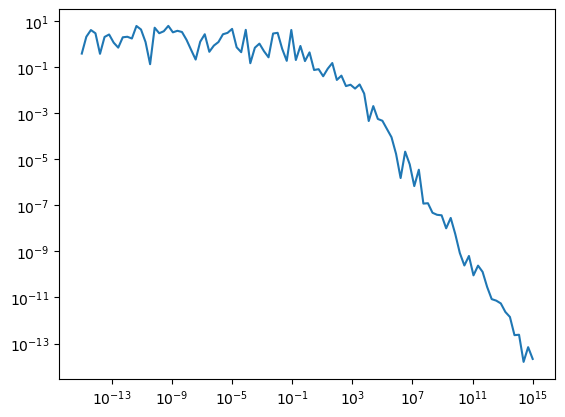

In [63]:
plt.loglog(betas, norms)
plt.show()

In [65]:
null_space(Atilde.T).shape

(10, 7)

In [94]:
beta = 1e4
np.random.seed(0)
b = np.random.normal(size=m)
xker = K @ (AKpinv @ b)
c = b - (A @ xker)
Atilde = A @ Lopinv
Q = beta*(Atilde @ Atilde.T) + np.eye(Atilde.shape[0])
Qinv = np.linalg.inv(Q)
P = Atilde.T @ Atilde + beta*np.eye(Atilde.shape[1])
Pinv = np.linalg.inv(P)

In [95]:
null_space( Qinv @ Atilde @ Atilde.T @ Qinv   )

array([[ 0.19523995, -0.12920898, -0.02507773],
       [ 0.24925983,  0.11840291,  0.0406716 ],
       [ 0.32910001,  0.3334655 , -0.49738299],
       [-0.42098512,  0.1211389 , -0.13712756],
       [-0.17555376,  0.07447047, -0.80526696],
       [-0.18760583,  0.35398093,  0.13897087],
       [ 0.04901658,  0.1876776 ,  0.06826293],
       [-0.61753536, -0.3949974 , -0.04415481],
       [ 0.35999357, -0.71379768, -0.19628906],
       [-0.18668859, -0.10867667, -0.13644218]])

In [126]:
null_space(Atilde).shape

(5, 0)